# Loading weather data for Daggett, CA with PySAM

Daggett, CA (Mojave Desert, ~34.85°N, 116.78°W) is the classic default site in NREL's System Advisor Model (SAM). This notebook:

1. Gets a typical meteorological year (TMY) weather file for Daggett by downloading a fresh NSRDB TMY file with `PySAM.ResourceTools.FetchResourceFiles`, which needs a free developer API key.
2. Loads it into PySAM's `solar_resource_data` format with `PySAM.ResourceTools.SAM_CSV_to_solar_data`.
3. Explores the data with pandas and matplotlib.
4. Passes the weather data straight into a PySAM model (PVWatts v8) to show it works.

**Setup:** `pip install nlr-pysam pandas matplotlib requests`

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import PySAM
import PySAM.ResourceTools as tools
import PySAM.Pvwattsv8 as pvwatts

print("PySAM version:", PySAM.__version__)

/Users/rciez/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


PySAM version: 8.0.0


## 1. Get the weather file


### fetch a fresh file from the NSRDB

`FetchResourceFiles` downloads data from NLrR's NSRDB API. Get a free key at https://developer.nlr.gov/signup/, and fill in the two variables below. The default dataset is the NSRDB GOES TMY v4 (60-minute).

In [ ]:
#NLR_API_KEY = "YOUR_API_KEY"
#NLR_API_EMAIL = "you@example.com"

DAGGETT_LON_LAT = (-116.78, 34.85)   # (lon, lat) -- note the order

DATA_DIR = 'weather_data'

fetcher = tools.FetchResourceFiles(
    tech="solar",
    nrel_api_key=NLR_API_KEY, #this is still a holdover with nrel
    nrel_api_email=NLR_API_EMAIL,  #this is still a holdover with nrel
    resource_type="nsrdb-GOES-tmy-v4-0-0",
    resource_year="tmy",
    resource_interval_min=60,
    resource_dir=DATA_DIR,
    )
fetcher.fetch([DAGGETT_LON_LAT])
weather_file = fetcher.resource_file_paths[0]

print("Weather file:", weather_file)


Starting data download for solar using 1 thread workers.
File already exists. Skipping download: weather_data/nsrdb_34.85_-116.78_nsrdb-GOES-tmy-v4-0-0_60_tmy.csv
Weather file: weather_data/nsrdb_34.85_-116.78_nsrdb-GOES-tmy-v4-0-0_60_tmy.csv


## 2. Load into PySAM's `solar_resource_data` format

`SAM_CSV_to_solar_data` reads the two header rows (site metadata) and the hourly columns, and returns a dictionary with SAM's variable names:

| key | meaning | units |
|---|---|---|
| `lat`, `lon`, `elev`, `tz` | site latitude, longitude, elevation, UTC offset | °, °, m, h |
| `gh`, `dn`, `df` | global horizontal, direct normal, diffuse horizontal irradiance | W/m² |
| `tdry`, `tdew` | dry-bulb and dew-point temperature | °C |
| `wspd`, `wdir` | wind speed and direction | m/s, ° |
| `pres` | pressure | mbar |
| `alb` | surface albedo | – |

In [3]:
solar_data = tools.SAM_CSV_to_solar_data(weather_file)

print("Keys:", list(solar_data.keys()))
print(f"Latitude  {solar_data['lat']:.2f}°")
print(f"Longitude {solar_data['lon']:.2f}°")
print(f"Elevation {solar_data['elev']:.0f} m")
print(f"Time zone UTC{solar_data['tz']:+.0f}")
print("Hourly records:", len(solar_data['gh']))

Keys: ['tz', 'elev', 'lat', 'lon', 'year', 'month', 'day', 'hour', 'minute', 'dn', 'df', 'gh', 'wspd', 'tdry', 'wdir', 'pres', 'tdew', 'rhum', 'alb']
Latitude  34.85°
Longitude -116.78°
Elevation 594 m
Time zone UTC-8
Hourly records: 8760


The file header also records the data source; peek at the first lines directly:

In [4]:
with open(weather_file) as f:
    for _ in range(3):
        print(f.readline().rstrip()[:150])

Source,Location ID,City,State,Country,Latitude,Longitude,Time Zone,Elevation,Local Time Zone,Clearsky DHI Units,Clearsky DNI Units,Clearsky GHI Units,
NSRDB,229640,-,-,-,34.85,-116.78,-8,594,-8,w/m2,w/m2,w/m2,c,w/m2,w/m2,w/m2,Degree,c,mbar,%,cm,Degrees,m/s,,Clear,Probably Clear,Fog,Water,Super-Cooled
Year,Month,Day,Hour,Minute,Temperature,Alpha,Aerosol Optical Depth,Asymmetry,Clearsky DHI,Clearsky DNI,Clearsky GHI,Cloud Fill Flag,Cloud Type,Dew Poi


## 3. Explore the data with pandas

TMY files stitch together months from different years, so the `year` column varies. We build the index with a single dummy year (non-leap) so the 8760 hours form one continuous series. NSRDB timestamps are in local standard time (no daylight saving).

In [5]:
ts_keys = ["year", "month", "day", "hour", "minute",
           "gh", "dn", "df", "tdry", "tdew", "wspd", "wdir", "pres", "alb"]
df = pd.DataFrame({k: solar_data[k] for k in ts_keys if k in solar_data})

df.index = pd.to_datetime(dict(year=2023, month=df.month, day=df.day,
                               hour=df.hour, minute=df.minute))
df.index.name = "local standard time"
df.head()

,year,month,day,hour,minute,gh,dn,df,tdry,tdew,wspd,wdir,pres,alb
local standard time,,,,,,,,,,,,,,
2023-01-01 00:30:00,1999.0,1.0,1.0,0.0,30.0,0.0,0.0,0.0,4.2,-6.2,1.9,358.0,945.0,0.29
2023-01-01 01:30:00,1999.0,1.0,1.0,1.0,30.0,0.0,0.0,0.0,3.7,-6.3,1.8,357.0,946.0,0.29
2023-01-01 02:30:00,1999.0,1.0,1.0,2.0,30.0,0.0,0.0,0.0,3.3,-6.3,1.9,356.0,946.0,0.29
2023-01-01 03:30:00,1999.0,1.0,1.0,3.0,30.0,0.0,0.0,0.0,2.9,-6.2,2.0,356.0,947.0,0.29
2023-01-01 04:30:00,1999.0,1.0,1.0,4.0,30.0,0.0,0.0,0.0,2.4,-6.3,2.0,355.0,948.0,0.29


In [6]:
df[["gh", "dn", "df", "tdry", "wspd"]].describe().round(1)

,gh,dn,df,tdry,wspd
count,8760.0,8760.0,8760.0,8760.0,8760.0
mean,246.6,324.1,53.6,19.6,3.1
std,329.3,396.5,76.8,10.0,1.8
min,0.0,0.0,0.0,-1.6,0.1
25%,0.0,0.0,0.0,11.3,1.5
50%,8.0,0.0,8.0,18.6,2.8
75%,487.0,775.0,87.0,26.9,4.3
max,1081.0,1032.0,524.0,44.9,11.2


In [7]:
annual = pd.Series({
    "GHI (kWh/m²/yr)": df.gh.sum() / 1000,
    "DNI (kWh/m²/yr)": df.dn.sum() / 1000,
    "DHI (kWh/m²/yr)": df.df.sum() / 1000,
    "Mean dry-bulb temp (°C)": df.tdry.mean(),
    "Max dry-bulb temp (°C)": df.tdry.max(),
    "Mean wind speed (m/s)": df.wspd.mean(),
})
annual.round(1)

GHI (kWh/m²/yr)            2160.0
DNI (kWh/m²/yr)            2839.4
DHI (kWh/m²/yr)             469.8
Mean dry-bulb temp (°C)      19.6
Max dry-bulb temp (°C)       44.9
Mean wind speed (m/s)         3.1
dtype: float64

### Monthly irradiation and temperature

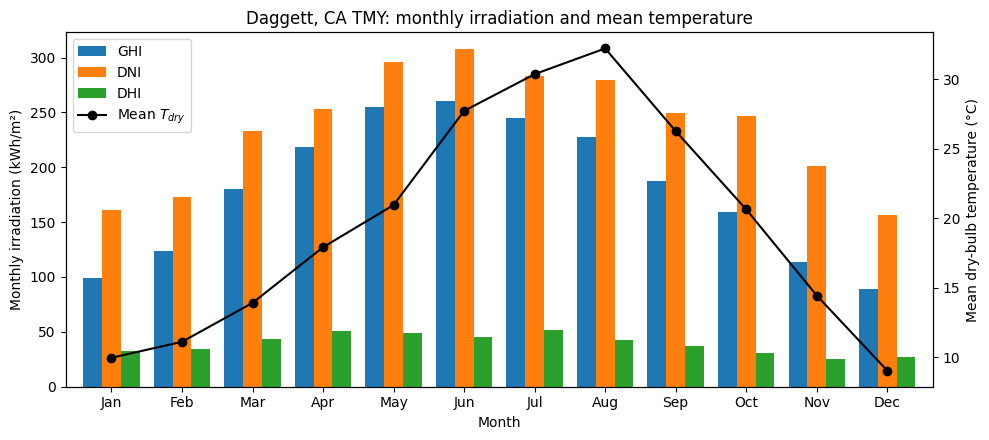

In [8]:
monthly = pd.DataFrame({
    "GHI": df.gh.resample("MS").sum() / 1000,
    "DNI": df.dn.resample("MS").sum() / 1000,
    "DHI": df.df.resample("MS").sum() / 1000,
})
monthly.index = monthly.index.strftime("%b")
tmean = df.tdry.resample("MS").mean().values

fig, ax = plt.subplots(figsize=(10, 4.5))
monthly.plot.bar(ax=ax, width=0.8, rot=0)
ax.set_ylabel("Monthly irradiation (kWh/m²)")
ax.set_xlabel("Month")
ax.set_title("Daggett, CA TMY: monthly irradiation and mean temperature")

ax2 = ax.twinx()
ax2.plot(range(12), tmean, "k-o", label="Mean $T_{dry}$")
ax2.set_ylabel("Mean dry-bulb temperature (°C)")

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
fig.tight_layout()
plt.show()

### A clear summer week and a winter week

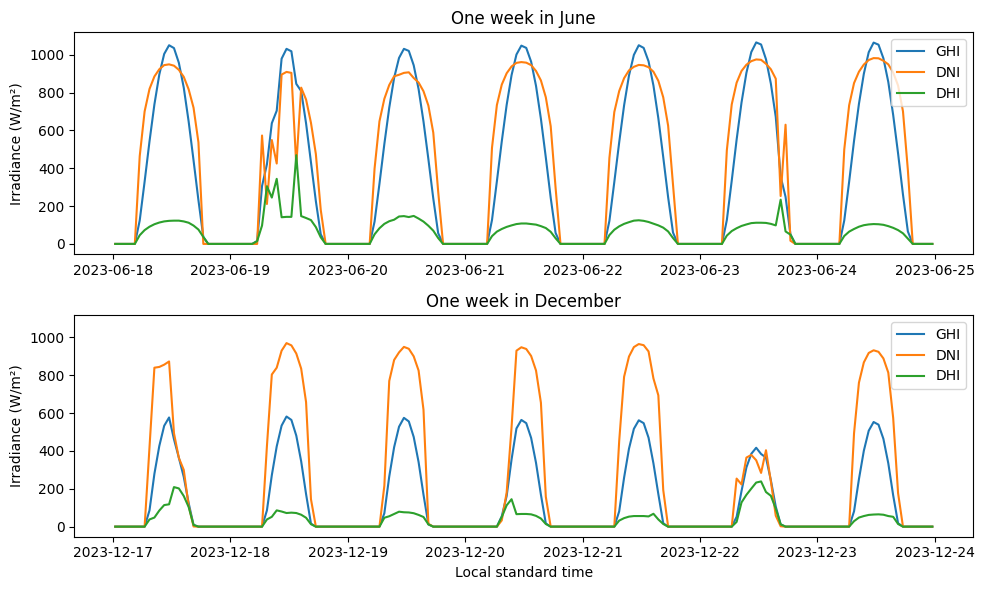

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharey=True)
for ax, (start, label) in zip(axes, [("2023-06-18", "June"), ("2023-12-17", "December")]):
    wk = df.loc[start: pd.Timestamp(start) + pd.Timedelta(days=7)]
    ax.plot(wk.index, wk.gh, label="GHI")
    ax.plot(wk.index, wk.dn, label="DNI")
    ax.plot(wk.index, wk.df, label="DHI")
    ax.set_ylabel("Irradiance (W/m²)")
    ax.set_title(f"One week in {label}")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Local standard time")
fig.tight_layout()
plt.show()

### Hour-of-day × day-of-year heat map of GHI

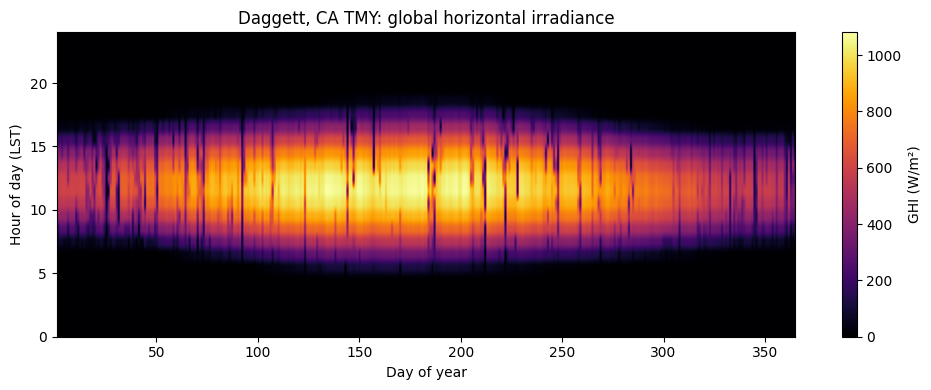

In [10]:
grid = df.gh.values.reshape(365, 24).T   # rows = hour, cols = day

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(grid, aspect="auto", origin="lower", cmap="inferno",
               extent=[1, 365, 0, 24])
ax.set_xlabel("Day of year")
ax.set_ylabel("Hour of day (LST)")
ax.set_title("Daggett, CA TMY: global horizontal irradiance")
fig.colorbar(im, ax=ax, label="GHI (W/m²)")
fig.tight_layout()
plt.show()

## 4. Use the weather data in a PySAM model

The `solar_resource_data` dictionary can be handed to any PySAM solar model in place of a file path. Here: a 4 kW PVWatts v8 system (default 20° tilt, south-facing). To use the file path instead, set `model.SolarResource.solar_resource_file = weather_file`.

In [11]:
model = pvwatts.default("PVWattsNone")
model.SolarResource.solar_resource_data = solar_data
model.SystemDesign.system_capacity = 4.0     # kW DC
model.execute()

out = model.Outputs
print(f"Annual AC energy:  {out.annual_energy:,.0f} kWh")
print(f"Capacity factor:   {out.capacity_factor:.1f} %")
print(f"Specific yield:    {out.kwh_per_kw:,.0f} kWh/kW")

Annual AC energy:  7,303 kWh
Capacity factor:   20.8 %
Specific yield:    1,826 kWh/kW


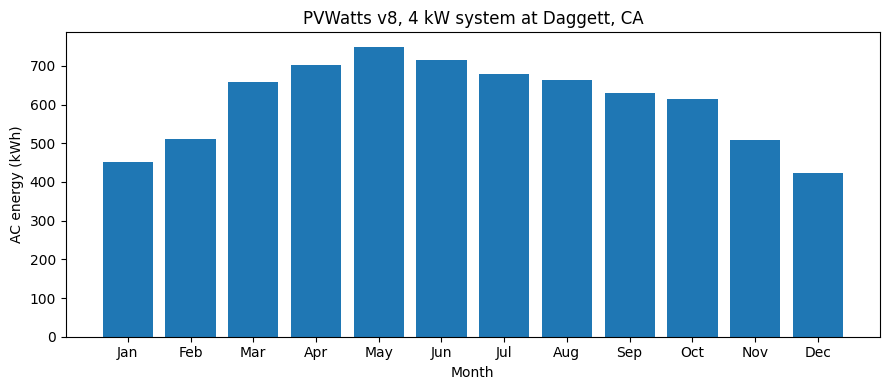

In [12]:
months = pd.date_range("2023-01-01", periods=12, freq="MS").strftime("%b")
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(months, out.ac_monthly)
ax.set_xlabel("Month")
ax.set_ylabel("AC energy (kWh)")
ax.set_title("PVWatts v8, 4 kW system at Daggett, CA")
fig.tight_layout()
plt.show()

## 5. Exploring electricity rate tools

The `solar_resource_data` dictionary can be handed to any PySAM solar model in place of a file path. Here: a 4 kW PVWatts v8 system (default 20° tilt, south-facing). To use the file path instead, set `model.SolarResource.solar_resource_file = weather_file`.